In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

## define the dataset path

In [13]:
DATASET_PATH = Path(
    r"D:\py\Eye-Disease-Detection-system\dataset"
)

print(os.listdir(DATASET_PATH))

['cataract', 'conjunctivitis', 'labels.csv', 'normal', 'pterygium']


In [14]:
class_labels = {
    "normal": 0,
    "cataract": 1,
    "conjunctivitis": 2,
    "pterygium": 3
}

data = []

for class_name, label in class_labels.items():

    folder_path = DATASET_PATH / class_name

    for image_path in folder_path.rglob("*"):

        if image_path.suffix.lower() in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:

            data.append({
                "image_path": str(image_path),
                "class_name": class_name,
                'label': label
            })

df = pd.DataFrame(data)

df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total images:", len(df))

df.head()

Total images: 4232


,image_path,class_name,label
0,D:\py\Eye-Disease-Detection-system\dataset\con...,conjunctivitis,2
1,D:\py\Eye-Disease-Detection-system\dataset\cat...,cataract,1
2,D:\py\Eye-Disease-Detection-system\dataset\con...,conjunctivitis,2
3,D:\py\Eye-Disease-Detection-system\dataset\cat...,cataract,1
4,D:\py\Eye-Disease-Detection-system\dataset\cat...,cataract,1


In [15]:
print(df["class_name"].value_counts())

class_name
conjunctivitis    1293
cataract          1257
normal             882
pterygium          800
Name: count, dtype: int64


#### sample distribution

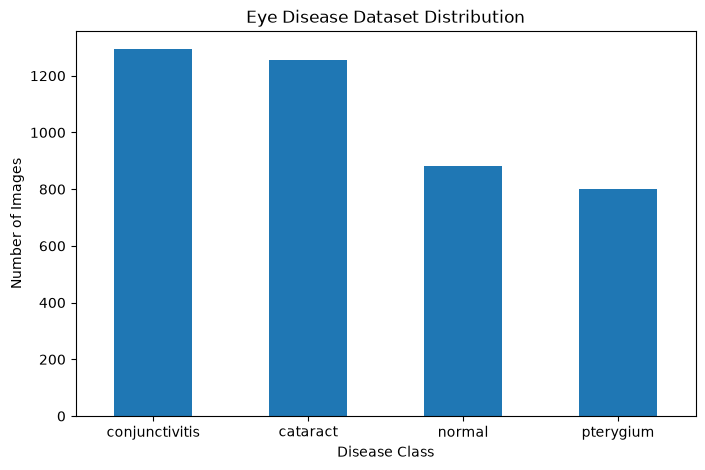

In [16]:
plt.figure(figsize=(8, 5))

df["class_name"].value_counts().plot(
    kind="bar"
)

plt.title("Eye Disease Dataset Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

### Display sample images


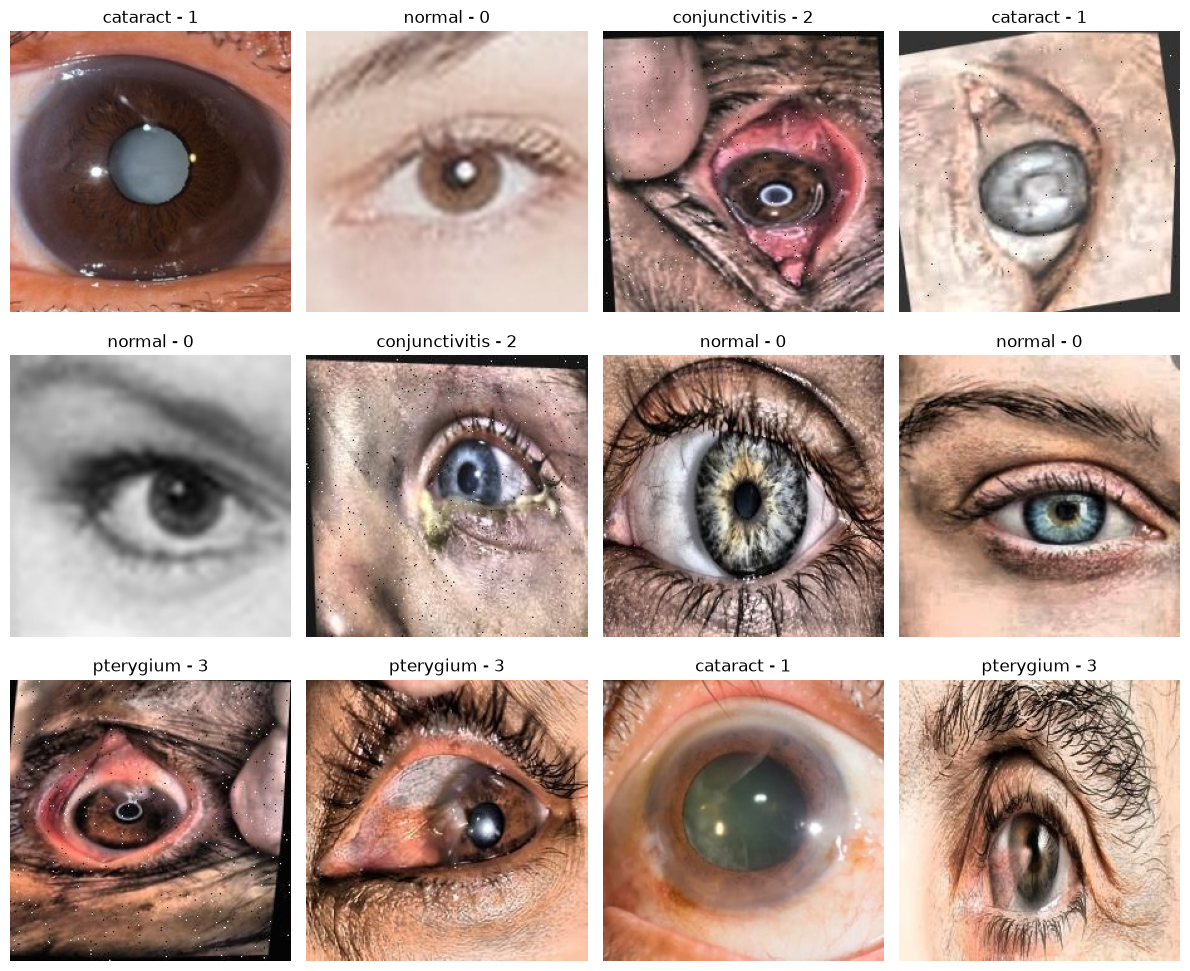

In [17]:
plt.figure(figsize=(12, 10))

samples = df.sample(
    min(12, len(df)),
    random_state=42
)

for i, (_, row) in enumerate(samples.iterrows()):

    image = Image.open(
        row["image_path"]
    ).convert("RGB")

    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"{row['class_name']} - {row['label']}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
df.to_csv(
    DATASET_PATH / "labels.csv",
    index=False
)

print("Labels saved successfully!")

Labels saved successfully!


In [20]:
image_sample_path = df['image_path'][0]

with Image.open(image_sample_path) as img:
    width, height = img.size
    channels = len(img.getbands())

print(f"{width} x {height} pixels, {channels} chanels")


224 x 224 pixels, 3 chanels
